# PyTorch. От тензоров к полносвязным моделям

Разберём операции над тензорами и обучение моделей для регрессии и классификации.
Начнём с одного линейного слоя, затем соединим несколько слоёв через `nn.Sequential`.
Для каждой задачи подготовим данные, зададим функцию потерь и напишем цикл обучения.

## Импорт

In [1]:
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import Dataset, TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from IPython.display import display

torch.manual_seed(42)
torch.set_printoptions(precision=4, sci_mode=False)

## 1. Тензоры и знакомые операции

### 1.1. Создадим массив чисел

Тензор в этой работе представляет собой многомерный массив.
В матрице признаков строки будут соответствовать объектам, а столбцы — их признакам.
`torch.tensor` создаёт тензор из переданных значений. Аргумент `dtype` задаёт тип элементов [1].

Форма `(2, 3)` означает две строки и три столбца. Свойство `ndim` возвращает число осей, а `numel()` — число элементов.
Для вычислений модели будем преимущественно использовать `float32`.

In [2]:
a = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float32)
x = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)

print("NumPy\n", a * 2 + 1)
print("PyTorch\n", x * 2 + 1)
print("Форма", tuple(x.shape), "Осей", x.ndim, "Элементов", x.numel())
print("Тип", x.dtype, "Устройство", x.device)
print("Нули\n", torch.zeros(2, 3))
print("Равномерная сетка", torch.linspace(-1, 1, 5))
print("Случайные числа", torch.randn(3, generator=torch.Generator().manual_seed(7)))

NumPy
 [[ 3.  5.  7.]
 [ 9. 11. 13.]]
PyTorch
 tensor([[ 3.,  5.,  7.],
        [ 9., 11., 13.]])
Форма (2, 3) Осей 2 Элементов 6
Тип torch.float32 Устройство cpu
Нули
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
Равномерная сетка tensor([-1.0000, -0.5000,  0.0000,  0.5000,  1.0000])
Случайные числа tensor([-0.1468,  0.7861,  0.9468])


### 1.2. Выберем элементы и вычислим средние

Индексация начинается с нуля. Запись `x[:, 1]` выбирает второй столбец, а `x[x > 3]` — элементы, удовлетворяющие условию.
При `mean(dim=0)` усредняются строки и остаётся одно значение для каждого столбца.
При `mean(dim=1)` получаем среднее каждой строки.

`keepdim=True` сохраняет усреднённую ось с длиной один. Это позволяет затем вычесть из каждой строки её собственное среднее.
При сложении форм `(2, 3)` и `(3,)` один вектор участвует в вычислениях для обеих строк.
Такое согласование форм называют broadcasting. Оно не требует явно создавать копию вектора для каждой строки [1].

In [3]:
x = torch.tensor([[1., 2., 3.], [4., 5., 6.]])
print("Второй столбец", x[:, 1])
print("Элементы больше трёх", x[x > 3])
print("Средние столбцов", x.mean(dim=0))
row_means = x.mean(dim=1, keepdim=True)
print("Средние строк", row_means, "Форма", tuple(row_means.shape))
print("Центрирование строк\n", x - row_means)
print("Смещение столбцов\n", x + torch.tensor([10., 20., 30.]))

Второй столбец tensor([2., 5.])
Элементы больше трёх tensor([4., 5., 6.])
Средние столбцов tensor([2.5000, 3.5000, 4.5000])
Средние строк tensor([[2.],
        [5.]]) Форма (2, 1)
Центрирование строк
 tensor([[-1.,  0.,  1.],
        [-1.,  0.,  1.]])
Смещение столбцов
 tensor([[11., 22., 33.],
        [14., 25., 36.]])


### 1.3. Различим два умножения

Оператор `*` перемножает соответствующие элементы. Оператор `@` выполняет матричное умножение.
В произведении матриц `(N, d) @ (d, k)` результат имеет форму `(N, k)`.
Его элемент получается суммированием произведений строки первой матрицы и столбца второй.

In [4]:
a = torch.tensor([[1., 2.], [3., 4.]])
b = torch.tensor([[5., 6.], [7., 8.]])
print("Поэлементное произведение\n", a * b)
print("Матричное произведение\n", a @ b)
print("Первый элемент вручную", 1 * 5 + 2 * 7)

Поэлементное произведение
 tensor([[ 5., 12.],
        [21., 32.]])
Матричное произведение
 tensor([[19., 22.],
        [43., 50.]])
Первый элемент вручную 19


### 1.4. Изменим форму

`reshape` меняет форму при сохранении числа элементов. `unsqueeze` добавляет ось длины один, а `squeeze(dim)` удаляет указанную ось, если её длина равна одному.
Транспонирование матрицы меняет местами строки и столбцы. Замена формы через `reshape` выполняет другую операцию.

Ответы регрессии будем хранить столбцом `(N, 1)`, даже когда для каждого объекта предсказывается одно число.
Позже это позволит непосредственно сопоставить выход `Linear(d, 1)` с правильными ответами.

In [5]:
v = torch.arange(6, dtype=torch.float32)
matrix = v.reshape(2, 3)
print("Матрица\n", matrix)
print("Транспонирование\n", matrix.T)
print("Другая раскладка элементов\n", matrix.reshape(3, 2))

targets = torch.tensor([1., 2., 3.])
print("Вектор", targets.shape, "Столбец", targets.unsqueeze(1).shape)
one_prediction = torch.tensor([[2.5]])
print("Без указания оси", one_prediction.squeeze().shape)
print("Только последняя ось", one_prediction.squeeze(-1).shape)

Матрица
 tensor([[0., 1., 2.],
        [3., 4., 5.]])
Транспонирование
 tensor([[0., 3.],
        [1., 4.],
        [2., 5.]])
Другая раскладка элементов
 tensor([[0., 1.],
        [2., 3.],
        [4., 5.]])
Вектор torch.Size([3]) Столбец torch.Size([3, 1])
Без указания оси torch.Size([])
Только последняя ось torch.Size([1])


### 1.5. Передадим данные между NumPy и PyTorch

`torch.from_numpy` создаёт CPU-тензор, разделяющий память с исходным массивом [1].
Изменение одного представления видно в другом. Метод `clone()` создаёт независимую копию.
Тип данных также сохраняется. Поэтому массив NumPy с типом `float64` при необходимости явно переводят в `float32`.

In [6]:
a = np.array([1., 2., 3.], dtype=np.float32)
x = torch.from_numpy(a)
x_copy = x.clone()
a[0] = 100
print("Общая память", x)
print("Независимая копия", x_copy)
print("Обратно в NumPy", x_copy.numpy())

Общая память tensor([100.,   2.,   3.])
Независимая копия tensor([1., 2., 3.])
Обратно в NumPy [1. 2. 3.]


### 1.6. Устройство вычислений

Метод `.to(device)` переносит тензор или параметры модели на выбранное устройство.
Входные данные и параметры слоя должны находиться на одном устройстве.
В этом примере используем CPU.
Для доступной видеокарты NVIDIA устройство можно задать как `torch.device("cuda")`.

In [7]:
device = torch.device("cpu")
x_device = torch.tensor([[1., 2.]]).to(device)
print("Устройство", x_device.device)
print("Возврат на CPU", x_device.cpu())

Устройство cpu
Возврат на CPU tensor([[1., 2.]])


## 2. Линейный слой и последовательная модель

### 2.1. Один ответ из нескольких признаков

Пусть объект описан тремя числами. Умножим каждый признак на свой вес и прибавим свободный член.

$$\hat y=w_1x_1+w_2x_2+w_3x_3+b.$$

Сначала зададим параметры сами и рассмотрим вклад каждого признака.

In [8]:
x = torch.tensor([2., 3., 4.])
w = torch.tensor([0.5, -1., 2.])
b = torch.tensor(1.)
print("Вклады признаков", x * w)
print("Ответ", (x * w).sum() + b)
print("Через матричную операцию", x @ w + b)

Вклады признаков tensor([ 1., -3.,  8.])
Ответ tensor(7.)
Через матричную операцию tensor(7.)


### 2.2. Несколько объектов и несколько ответов

Разместим объекты по строкам матрицы $X$, а веса каждого выхода — по строкам матрицы $W$.
Тогда все ответы вычисляются одновременно.

$$Y=XW^T+b.$$

Для $N$ объектов с $d$ признаками и $k$ выходами формы равны `(N, d)`, `(k, d)` и `(k,)`.
После транспонирования весов результат имеет форму `(N, k)` [2].
Смещение добавляется к каждой строке результата.

In [9]:
X = torch.tensor([[2., 3., 4.], [1., 0., 2.]])
W = torch.tensor([[0.5, -1., 2.], [1., 1., -0.5]])
b = torch.tensor([1., -2.])
Y_manual = X @ W.T + b
print("Формы", X.shape, W.T.shape, Y_manual.shape)
print(Y_manual)

Формы torch.Size([2, 3]) torch.Size([3, 2]) torch.Size([2, 2])
tensor([[ 7.0000,  1.0000],
        [ 5.5000, -2.0000]])


### 2.3. Повторим вычисление через `nn.Linear`

`nn.Linear(3, 2)` хранит две строки по три веса и два смещения [2].
Число объектов в пакете в аргументы слоя не входит. При наличии смещения преобразование математически является аффинным.
Название «линейный слой» будем использовать в соответствии с API.

Скопируем известные параметры. Блок `torch.no_grad()` нужен здесь для служебного присваивания без построения графа производных.
Создание слоя само по себе ещё не обучает его.

In [10]:
layer = nn.Linear(3, 2)
with torch.no_grad():
    layer.weight.copy_(W)
    layer.bias.copy_(b)

Y_layer = layer(X)
print("Ответ слоя\n", Y_layer)
for name, parameter in layer.named_parameters():
    print(name, tuple(parameter.shape), "requires_grad", parameter.requires_grad)
print("Всего параметров", sum(p.numel() for p in layer.parameters()))

Ответ слоя
 tensor([[ 7.0000,  1.0000],
        [ 5.5000, -2.0000]], grad_fn=<AddmmBackward0>)
weight (2, 3) requires_grad True
bias (2,) requires_grad True
Всего параметров 8


Число параметров `Linear(d, k)` со смещением равно $dk+k$.
Данные `X` не входят в эту сумму. Увеличение размера пакета меняет объём вычислений и промежуточных результатов, но не число весов слоя.

### 2.4. Соединим слои

Первый слой преобразует два признака в четыре промежуточных значения.
`ReLU` применяет к каждому значению функцию $\max(0,z)$.
Последний слой получает эти четыре значения и вычисляет один ответ.

$$h=\operatorname{ReLU}(XW_1^T+b_1),\qquad \hat y=hW_2^T+b_2.$$

Сначала вызовем слои по отдельности, затем передадим те же экземпляры в `nn.Sequential`.
Контейнер применяет их последовательно и собирает параметры вложенных слоёв [3].

In [11]:
torch.manual_seed(7)
X_small = torch.tensor([[1., -2.], [0., 3.]])
first = nn.Linear(2, 4)
activation = nn.ReLU()
last = nn.Linear(4, 1)

z = first(X_small)
h = activation(z)
y_separate = last(h)
sequence = nn.Sequential(first, activation, last)
print("После первого слоя\n", z)
print("После ReLU\n", h)
print("Ответ\n", sequence(X_small))

После первого слоя
 tensor([[ 0.7108,  0.2782,  0.3360, -0.7092],
        [-1.4683,  1.1624,  0.1840,  0.6225]], grad_fn=<AddmmBackward0>)
После ReLU
 tensor([[0.7108, 0.2782, 0.3360, 0.0000],
        [0.0000, 1.1624, 0.1840, 0.6225]], grad_fn=<ReluBackward0>)
Ответ
 tensor([[-0.0313],
        [-0.2187]], grad_fn=<AddmmBackward0>)


In [12]:
current = X_small
for number, operation in enumerate(sequence):
    current = operation(current)
    print(number, type(operation).__name__, tuple(current.shape))
print("Первый слой", sequence[0])
print("Число параметров", sum(p.numel() for p in sequence.parameters()))

0 Linear (2, 4)
1 ReLU (2, 4)
2 Linear (2, 1)
Первый слой Linear(in_features=2, out_features=4, bias=True)
Число параметров 17


### 2.5. Последовательность без функции активации

Два линейных слоя без активации можно записать как один слой.
У него будут другие веса и смещение.

$$W_{\mathrm{общ}}=W_2W_1,\qquad b_{\mathrm{общ}}=W_2b_1+b_2.$$

Вставка `ReLU` меняет вычисление промежуточных значений.
Такую последовательность в общем случае уже нельзя заменить одним линейным слоем.

In [13]:
torch.manual_seed(7)
first = nn.Linear(2, 3)
second = nn.Linear(3, 1)
W_total = second.weight @ first.weight
b_total = second.weight @ first.bias + second.bias
separate = second(first(X_small))
combined = X_small @ W_total.T + b_total
print("Два слоя без активации\n", separate.detach())
print("Объединённое преобразование\n", combined.detach())
print("С ReLU между слоями\n", second(torch.relu(first(X_small))).detach())

Два слоя без активации
 tensor([[-0.0839],
        [-0.6144]])
Объединённое преобразование
 tensor([[-0.0839],
        [-0.6144]])
С ReLU между слоями
 tensor([[-0.0486],
        [ 0.1019]])


## 3. Производные и один шаг обучения

### 3.1. Вычислим производную простого выражения

У тензора с `requires_grad=True` PyTorch отслеживает операции, необходимые для обратного распространения производных [4].
Для $q=a^2$ производная равна $2a$. Вызов `q.backward()` записывает её в `a.grad`.
Само значение `a` от этого не изменяется.

Граф создаётся при выполнении операций. Во второй строке с `backward()` ниже вычисляется новое выражение `a ** 2`.
Повторное использование уже обработанного графа здесь не требуется.

In [14]:
a = torch.tensor(3., requires_grad=True)
q = a ** 2
q.backward()
print("q", q.item(), "dq/da", a.grad.item(), "a", a.item())
(a ** 2).backward()
print("Второй расчёт без очистки", a.grad.item())
a.grad = None
(a ** 2).backward()
print("После очистки", a.grad.item())

q 9.0 dq/da 6.0 a 3.0
Второй расчёт без очистки 12.0
После очистки 6.0


### 3.2. Сначала найдём предсказание и ошибку

Возьмём три пары чисел, удовлетворяющих зависимости $y=2x+1$.
Начнём с нулевых веса и смещения. Для каждого объекта модель выдаёт одно число.
Вход, предсказание и правильный ответ имеют форму `(3, 1)`.

Средний квадрат ошибки равен

$$L=\frac{1}{N}\sum_{i=1}^N(\hat y_i-y_i)^2.$$

`nn.MSELoss()` с настройками по умолчанию усредняет квадраты разностей по всем элементам [5].
При одном выходе на объект это совпадает с формулой выше.

In [15]:
x_step = torch.tensor([[1.], [2.], [3.]])
y_step = torch.tensor([[3.], [5.], [7.]])
step_model = nn.Linear(1, 1)
with torch.no_grad():
    step_model.weight.zero_()
    step_model.bias.zero_()

step_loss_function = nn.MSELoss()
step_optimizer = optim.SGD(step_model.parameters(), lr=0.1)
step_optimizer.zero_grad(set_to_none=True)
step_prediction = step_model(x_step)
step_loss = step_loss_function(step_prediction, y_step)
print("Предсказания", step_prediction.detach().flatten())
print("Ошибка вручную", ((step_prediction - y_step) ** 2).mean().item())
print("MSELoss", step_loss.item())

Предсказания tensor([0., 0., 0.])
Ошибка вручную 27.66666603088379
MSELoss 27.66666603088379


### 3.3. Затем вычислим производные по параметрам

Для линейного ответа $\hat y_i=wx_i+b$ получаем

$$\frac{\partial L}{\partial w}=\frac{2}{N}\sum_i(\hat y_i-y_i)x_i,
\qquad
\frac{\partial L}{\partial b}=\frac{2}{N}\sum_i(\hat y_i-y_i).$$

Сравним эти выражения с результатом `backward()`. В многослойной модели PyTorch последовательно применяет правило дифференцирования сложной функции.
Ручное выведение производной для каждого нового слоя в цикле обучения не требуется [4].

In [16]:
step_loss.backward()
manual_dw = (2 * (step_prediction.detach() - y_step) * x_step).mean()
manual_db = (2 * (step_prediction.detach() - y_step)).mean()
print("dw вручную и автоматически", manual_dw.item(), step_model.weight.grad.item())
print("db вручную и автоматически", manual_db.item(), step_model.bias.grad.item())
print("Вес до шага", step_model.weight.item())

dw вручную и автоматически -22.66666603088379 -22.666667938232422
db вручную и автоматически -10.0 -10.0
Вес до шага 0.0


### 3.4. Изменим вес и смещение

Для SGD без дополнительных настроек обновление записывается как

$$\theta_{\mathrm{нов}}=\theta_{\mathrm{стар}}-\eta\nabla_\theta L.$$

В нашем примере $\eta=0{,}1$. Оптимизатор получает параметры модели и изменяет их после `optimizer.step()` [6].
Он использует уже вычисленные градиенты. Новый прямой проход нужен для вычисления ошибки после обновления.

`detach()` отделяет тензор от графа, а `item()` возвращает обычное число из одноэлементного тензора.
В журнал обучения будем записывать числа, не сохраняя граф каждой эпохи.

In [17]:
w_expected = step_model.weight.detach().clone() - 0.1 * step_model.weight.grad
b_expected = step_model.bias.detach().clone() - 0.1 * step_model.bias.grad
step_optimizer.step()
with torch.no_grad():
    loss_after_step = step_loss_function(step_model(x_step), y_step)
print("Новый вес", step_model.weight.item(), "Смещение", step_model.bias.item())
print("Ошибка до", step_loss.item(), "после", loss_after_step.item())

Новый вес 2.266666889190674 Смещение 1.0
Ошибка до 27.66666603088379 после 0.33185240626335144


Градиенты накапливаются, поэтому перед очередным независимым обновлением вызывается `zero_grad()`.
При `set_to_none=True` поле очищенного градиента становится `None`.
Веса модели при очистке не обнуляются [4, 6].

### 3.5. Проверим форму правильных ответов

Формы `(N, 1)` и `(N,)` представляют разные расположения осей.
Их разность по правилам broadcasting имеет форму `(N, N)`.
В такой матрице появляются сравнения предсказания одного объекта с ответами других объектов.
Проверять формы следует до вычисления потерь, а не только после появления ошибки.

In [18]:
prediction_column = torch.tensor([[1.], [2.], [3.]])
target_vector = torch.tensor([1., 2., 3.])
wrong_difference = prediction_column - target_vector
correct_difference = prediction_column - target_vector.unsqueeze(1)
print("Несогласованные формы дают", wrong_difference.shape)
print(wrong_difference)
print("После добавления оси", correct_difference.shape)

Несогласованные формы дают torch.Size([3, 3])
tensor([[ 0., -1., -2.],
        [ 1.,  0., -1.],
        [ 2.,  1.,  0.]])
После добавления оси torch.Size([3, 1])


## 4. Линейная регрессия на нескольких признаках

### 4.1. Подготовим наблюдения с известной зависимостью

Создадим 800 объектов с тремя признаками. Правильные ответы зададим по формуле

$$y=2x_1-3x_2+0{,}7x_3+1{,}5+\varepsilon,$$

где $\varepsilon$ — независимый нормальный шум со стандартным отклонением 0.35.
Коэффициенты известны только потому, что данные созданы для учебного опыта.
При обучении будем передавать модели признаки и наблюдаемые ответы, но не истинные коэффициенты.

In [19]:
rng = np.random.default_rng(42)
X_reg_raw = rng.normal(size=(800, 3)) * [1., 3., 0.5] + [0., 2., 1.]
true_weights = np.array([2., -3., 0.7])
true_bias = 1.5
y_reg_raw = X_reg_raw @ true_weights + true_bias + rng.normal(0, 0.35, 800)
reg_frame = pd.DataFrame(X_reg_raw, columns=["x1", "x2", "x3"])
reg_frame["y"] = y_reg_raw
display(reg_frame.head().round(3))

,x1,x2,x3,y
0,0.305,-1.120,1.375,6.276
1,0.941,-3.853,0.349,15.528
2,0.128,1.051,0.992,-0.606
3,-0.853,4.638,1.389,-13.393
4,0.066,5.382,1.234,-13.953


### 4.2. Разделим данные до вычисления статистик

Обучающая часть `train` используется для изменения параметров.
Проверочная часть `valid` позволит выбрать эпоху, на которой сохраняются веса.
Тестовая часть `test` остаётся для итогового расчёта ошибок после этого выбора.

Возьмём 60% объектов для обучения, 20% для проверки и 20% для теста.
Сначала отделяется 20% всех объектов. Затем четверть оставшихся 80% образует проверочную часть [10].
Для реальных временных или групповых наблюдений случайное разделение может быть неподходящим.
В данном опыте объекты создавались независимо.

In [20]:
reg_indices = np.arange(len(X_reg_raw))
reg_train_idx, reg_test_idx = train_test_split(
    reg_indices, test_size=0.2, random_state=42
)
reg_train_idx, reg_valid_idx = train_test_split(
    reg_train_idx, test_size=0.25, random_state=42
)
print("Train", len(reg_train_idx), "Valid", len(reg_valid_idx), "Test", len(reg_test_idx))

Train 480 Valid 160 Test 160


### 4.3. Приведём признаки к сопоставимому масштабу

Для каждого столбца обучающей части найдём среднее $\mu_j$ и стандартное отклонение $s_j$.
Преобразование имеет вид

$$\widetilde x_{ij}=\frac{x_{ij}-\mu_j}{s_j}.$$

Статистики вычисляются только по `train`. К `valid`, `test` и новым объектам применяется та же формула с уже найденными числами [11].
`correction=0` означает деление на $N$ при вычислении дисперсии.
`clamp_min` защищает знаменатель от нуля у постоянного столбца.

Входы имеют форму `(N, 3)`, ответы — `(N, 1)`. Целевую величину в этом опыте не масштабируем.

In [21]:
X_reg_all = torch.tensor(X_reg_raw, dtype=torch.float32)
y_reg_all = torch.tensor(y_reg_raw, dtype=torch.float32).reshape(-1, 1)
reg_mean = X_reg_all[reg_train_idx].mean(dim=0, keepdim=True)
reg_scale = X_reg_all[reg_train_idx].std(dim=0, correction=0, keepdim=True).clamp_min(1e-6)

X_reg_train = (X_reg_all[reg_train_idx] - reg_mean) / reg_scale
X_reg_valid = (X_reg_all[reg_valid_idx] - reg_mean) / reg_scale
X_reg_test = (X_reg_all[reg_test_idx] - reg_mean) / reg_scale
y_reg_train = y_reg_all[reg_train_idx]
y_reg_valid = y_reg_all[reg_valid_idx]
y_reg_test = y_reg_all[reg_test_idx]
print("Признаки", X_reg_train.shape, X_reg_train.dtype)
print("Ответы", y_reg_train.shape, y_reg_train.dtype)
print("Средние train после преобразования", X_reg_train.mean(dim=0))

Признаки torch.Size([480, 3]) torch.float32
Ответы torch.Size([480, 1]) torch.float32
Средние train после преобразования tensor([-0.0000, -0.0000, -0.0000])


### 4.4. Dataset и DataLoader

`Dataset` описывает доступ к одному объекту [7].
В конструкторе сохраним признаки и ответы.
Метод `__len__` вернёт число объектов, а `__getitem__` вернёт одну пару по её индексу.

Для уже подготовленных тензоров ту же задачу решает `TensorDataset`.
Он связывает элементы с одинаковым индексом по первой оси.

In [22]:
class PairsDataset(Dataset):
    def __init__(self, features, targets):
        self.features = features
        self.targets = targets

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.features[index], self.targets[index]

reg_train_dataset = PairsDataset(X_reg_train, y_reg_train)
reg_valid_dataset = PairsDataset(X_reg_valid, y_reg_valid)
reg_test_dataset = PairsDataset(X_reg_test, y_reg_test)

reg_tensor_dataset = TensorDataset(X_reg_train, y_reg_train)
print("Объект из своего Dataset", reg_train_dataset[0])
print("Объект из TensorDataset", reg_tensor_dataset[0])

Объект из своего Dataset (tensor([-0.8557,  0.9661,  0.7985]), tensor([-13.3926]))
Объект из TensorDataset (tensor([-0.8557,  0.9661,  0.7985]), tensor([-13.3926]))


`DataLoader` собирает отдельные объекты в пакеты [7].
Для признаков он объединяет векторы в матрицу `(B, 3)`.
Ответы регрессии образуют столбец `(B, 1)`.

Параметр `shuffle=True` меняет порядок объектов при очередном проходе.
Пары признаков и ответов при этом сохраняются.
Один проход по всем пакетам называют эпохой.
Для валидации и теста перемешивание отключим.

In [23]:
reg_train_loader = DataLoader(
    reg_train_dataset, batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(42)
)
reg_valid_loader = DataLoader(reg_valid_dataset, batch_size=128, shuffle=False)
reg_test_loader = DataLoader(reg_test_dataset, batch_size=128, shuffle=False)
reg_train_eval_loader = DataLoader(reg_train_dataset, batch_size=128, shuffle=False)

x_batch, y_batch = next(iter(reg_train_loader))
print("Признаки пакета", x_batch.shape)
print("Ответы пакета", y_batch.shape)
print("Пакетов в эпохе", len(reg_train_loader))

Признаки пакета torch.Size([64, 3])
Ответы пакета torch.Size([64, 1])
Пакетов в эпохе 8


### 4.5. Модель, функция потерь и оптимизатор

`Linear(3, 1)` вычисляет одно число по трём признакам.
Функцию активации на выходе не добавляем, поэтому ответ может быть и положительным, и отрицательным.
`MSELoss` сравнивает предсказание с правильным ответом.
Оптимизатор SGD изменяет параметры по вычисленным градиентам.

Сначала перенесём модель на устройство.
Затем передадим её параметры оптимизатору.

In [24]:
torch.manual_seed(42)
reg_model = nn.Linear(3, 1).to(device)
reg_loss_function = nn.MSELoss()
reg_optimizer = optim.SGD(reg_model.parameters(), lr=0.05)
print(reg_model)

Linear(in_features=3, out_features=1, bias=True)


### 4.6. Цикл обучения и валидации

Внутренний цикл обрабатывает один пакет за другим.
Сначала очищаем градиенты, затем получаем ответы модели и вычисляем потерю.
Вызов `backward()` находит градиенты.
Вызов `step()` обновляет параметры.

Для средней потери за эпоху умножаем потерю пакета на число объектов в нём.
Накопленную сумму делим на число объектов во всей части данных.
Так последний неполный пакет получает правильный вес.

После обучения за эпоху вызываем `eval()` и выполняем цикл валидации внутри `torch.no_grad()`.
`eval()` меняет режим некоторых слоёв, но сам по себе не отключает вычисление градиентов [8].
У `Linear` и `ReLU` вычисления в режимах `train` и `eval` одинаковы.

При уменьшении потери на `valid` сохраняем копию состояния модели через `deepcopy`.
Обычное присваивание `state_dict()` не создаёт независимую копию его тензоров [14].
После всех эпох возвращаем сохранённые параметры в модель.

In [25]:
reg_history_rows = []
reg_best_valid = float("inf")

for epoch in range(1, 51):
    reg_model.train()
    train_loss_sum = 0.0

    for x_batch, y_batch in reg_train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        reg_optimizer.zero_grad()
        prediction = reg_model(x_batch)
        loss = reg_loss_function(prediction, y_batch)
        loss.backward()
        reg_optimizer.step()
        train_loss_sum += loss.item() * len(y_batch)

    reg_model.eval()
    valid_loss_sum = 0.0
    with torch.no_grad():
        for x_batch, y_batch in reg_valid_loader:
            prediction = reg_model(x_batch.to(device))
            loss = reg_loss_function(prediction, y_batch.to(device))
            valid_loss_sum += loss.item() * len(y_batch)

    train_mse = train_loss_sum / len(reg_train_dataset)
    valid_mse = valid_loss_sum / len(reg_valid_dataset)
    reg_history_rows.append([epoch, train_mse, valid_mse])

    if valid_mse < reg_best_valid:
        reg_best_valid = valid_mse
        reg_best_epoch = epoch
        reg_best_state = deepcopy(reg_model.state_dict())

reg_model.load_state_dict(reg_best_state)
reg_model.eval()
reg_history = pd.DataFrame(reg_history_rows, columns=["epoch", "train_mse", "valid_mse"])

### 4.7. Рассмотрим ход обучения

Обучающая ошибка усреднена по пакетам, обработанным при разных состояниях модели внутри эпохи.
Проверочная ошибка вычислена с одним состоянием параметров после её завершения.
Поэтому эти два числа не являются измерениями полностью одинаковых условий.
На графике используется логарифмическая шкала ошибки.

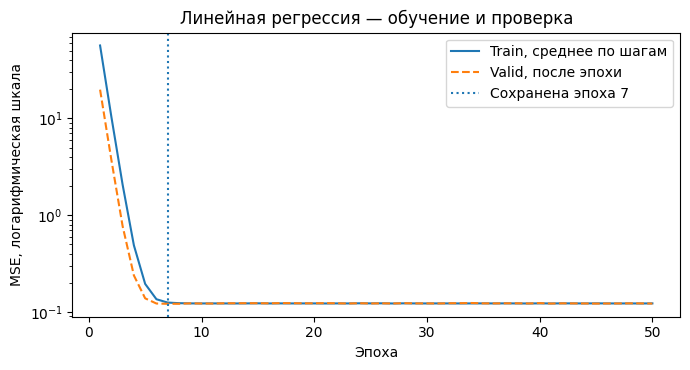

In [26]:
plt.figure(figsize=(7, 3.8))
plt.plot(reg_history.epoch, reg_history.train_mse, label="Train, среднее по шагам")
plt.plot(reg_history.epoch, reg_history.valid_mse, "--", label="Valid, после эпохи")
plt.axvline(reg_best_epoch, linestyle=":", label=f"Сохранена эпоха {reg_best_epoch}")
plt.yscale("log")
plt.xlabel("Эпоха")
plt.ylabel("MSE, логарифмическая шкала")
plt.title("Линейная регрессия — обучение и проверка")
plt.legend()
plt.tight_layout()
plt.show()

### 4.8. Оценим отложенные ответы

Теперь используем `test`. Средняя абсолютная ошибка и корень из среднего квадрата ошибки имеют те же единицы, что и целевая величина.

$$\mathrm{MAE}=\frac{1}{N}\sum_i|\hat y_i-y_i|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{N}\sum_i(\hat y_i-y_i)^2}.$$

Коэффициент $R^2$ сравнивает сумму квадратов ошибок с разбросом ответов относительно их среднего на оцениваемой части.

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

Для дополнительного ориентира предскажем всем объектам средний ответ **обучающей** части.
После просмотра тестовых результатов не следует подбирать по ним число эпох или архитектуру.

In [27]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    errors = y_pred - y_true
    denominator = np.sum((y_true - y_true.mean()) ** 2)
    return {
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "R²": 1 - np.sum(errors ** 2) / denominator if denominator > 0 else np.nan,
    }

reg_results_rows = []
reg_predictions = {}
reg_model.eval()

for part, loader in [("train", reg_train_eval_loader), ("test", reg_test_loader)]:
    all_targets = []
    all_predictions = []
    with torch.no_grad():
        for x_batch, y_batch in loader:
            prediction = reg_model(x_batch.to(device))
            all_predictions.append(prediction.cpu())
            all_targets.append(y_batch)

    targets = torch.cat(all_targets).numpy()
    predictions = torch.cat(all_predictions).numpy()
    reg_predictions[part] = predictions
    reg_results_rows.append({
        "Модель": "Linear(3, 1)", "Выборка": part,
        **regression_metrics(targets, predictions)
    })

reg_test_prediction = reg_predictions["test"]
reg_constant = np.full(len(y_reg_test), y_reg_train.mean().item())
reg_results_rows.append({
    "Модель": "Среднее train", "Выборка": "test",
    **regression_metrics(y_reg_test, reg_constant)
})
reg_results = pd.DataFrame(reg_results_rows)
display(reg_results.round(4))

,Модель,Выборка,MAE,RMSE,R²
0,"Linear(3, 1)",train,0.2860,0.3514,0.9984
1,"Linear(3, 1)",test,0.2880,0.3565,0.9985
2,Среднее train,test,6.9651,9.1198,-0.0048


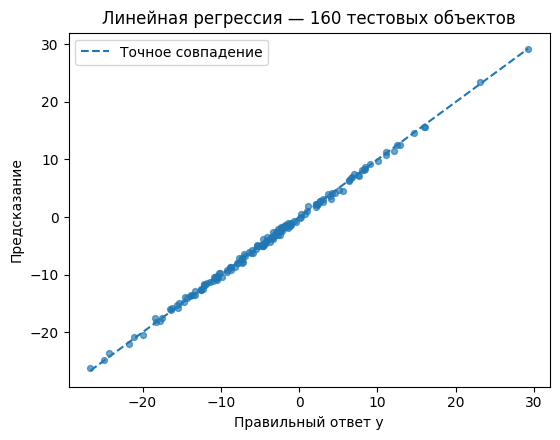

In [28]:
plt.figure(figsize=(5.7, 4.5))
plt.scatter(y_reg_test.numpy().ravel(), reg_test_prediction.ravel(), s=18, alpha=0.65)
reg_bounds = [float(y_reg_test.min()), float(y_reg_test.max())]
plt.plot(reg_bounds, reg_bounds, "--", label="Точное совпадение")
plt.xlabel("Правильный ответ y")
plt.ylabel("Предсказание")
plt.title("Линейная регрессия — 160 тестовых объектов")
plt.legend()
plt.tight_layout()
plt.show()

### 4.9. Вернём коэффициенты к исходным признакам

Обученный слой получает стандартизованные значения, поэтому его веса нельзя непосредственно сопоставлять с коэффициентами исходной формулы.
Подставляя преобразование признаков, получаем

$$w_j^{\mathrm{исх}}=\frac{w_j^{\mathrm{ст}}}{s_j},\qquad
b^{\mathrm{исх}}=b^{\mathrm{ст}}-\sum_j\frac{w_j^{\mathrm{ст}}\mu_j}{s_j}.$$

В таблице рядом показаны коэффициенты исходной формулы и обученной модели.

In [29]:
reg_weights_std = reg_model.weight.detach().cpu().numpy().ravel()
reg_bias_std = reg_model.bias.detach().cpu().item()
reg_weights_original = reg_weights_std / reg_scale.numpy().ravel()
reg_bias_original = reg_bias_std - np.sum(reg_weights_original * reg_mean.numpy().ravel())
display(pd.DataFrame({
    "Параметр": ["w1", "w2", "w3", "b"],
    "В формуле данных": [*true_weights, true_bias],
    "После обучения": [*reg_weights_original, reg_bias_original],
}).round(4))
manual_original_prediction = X_reg_raw[reg_test_idx] @ reg_weights_original + reg_bias_original

,Параметр,В формуле данных,После обучения
0,w1,2.0,1.9722
1,w2,-3.0,-2.9892
2,w3,0.7,0.6996
3,b,1.5,1.5141


## 5. Полносвязная сеть для нелинейной регрессии

### 5.1. Изменим зависимость, сохранив порядок работы

Создадим независимые наблюдения на отрезке $[-2{,}5,\,2{,}5]$.
Теперь правильные ответы задаются формулой

$$y=x^2+0{,}35x+\varepsilon,\qquad \varepsilon\sim\mathcal N(0,0{,}2^2).$$

Заранее сравним две модели. Первая содержит один линейный слой.
Вторая имеет два скрытых слоя по 32 значения с `ReLU` и один линейный выход.
Разбиение и порядок пакетов для моделей будут одинаковыми.

In [30]:
rng = np.random.default_rng(43)
X_curve_raw = rng.uniform(-2.5, 2.5, size=(600, 1))
y_curve_raw = X_curve_raw ** 2 + 0.35 * X_curve_raw + rng.normal(0, 0.2, size=(600, 1))
curve_train_idx, curve_test_idx = train_test_split(np.arange(600), test_size=0.2, random_state=42)
curve_train_idx, curve_valid_idx = train_test_split(curve_train_idx, test_size=0.25, random_state=42)
X_curve_all = torch.tensor(X_curve_raw, dtype=torch.float32)
y_curve_all = torch.tensor(y_curve_raw, dtype=torch.float32)
curve_mean = X_curve_all[curve_train_idx].mean(dim=0, keepdim=True)
curve_scale = X_curve_all[curve_train_idx].std(dim=0, correction=0, keepdim=True).clamp_min(1e-6)
X_curve_train = (X_curve_all[curve_train_idx] - curve_mean) / curve_scale
X_curve_valid = (X_curve_all[curve_valid_idx] - curve_mean) / curve_scale
X_curve_test = (X_curve_all[curve_test_idx] - curve_mean) / curve_scale
y_curve_train = y_curve_all[curve_train_idx]
y_curve_valid = y_curve_all[curve_valid_idx]
y_curve_test = y_curve_all[curve_test_idx]
print("Формы train", X_curve_train.shape, y_curve_train.shape)

Формы train torch.Size([360, 1]) torch.Size([360, 1])


### 5.2. Наборы данных и архитектуры

Для всех частей используем `TensorDataset`.
Сравним один линейный слой и сеть с двумя скрытыми слоями.
Внутри сети форма пакета меняется как `(B, 1) → (B, 32) → (B, 32) → (B, 1)`.
Функция `ReLU` не меняет форму тензора и не содержит обучаемых параметров.

In [31]:
curve_train_dataset = TensorDataset(X_curve_train, y_curve_train)
curve_valid_dataset = TensorDataset(X_curve_valid, y_curve_valid)
curve_test_dataset = TensorDataset(X_curve_test, y_curve_test)
curve_valid_loader = DataLoader(curve_valid_dataset, batch_size=128, shuffle=False)
curve_test_loader = DataLoader(curve_test_dataset, batch_size=128, shuffle=False)
curve_train_eval_loader = DataLoader(curve_train_dataset, batch_size=128, shuffle=False)

torch.manual_seed(42)
curve_models = {
    "Линейная": nn.Sequential(nn.Linear(1, 1)).to(device),
    "Полносвязная": nn.Sequential(
        nn.Linear(1, 32), nn.ReLU(),
        nn.Linear(32, 32), nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device),
}
curve_loss_function = nn.MSELoss()

### 5.3. Обучение двух моделей

Для каждой модели создаём свой оптимизатор Adam [6].
Он использует накопленные оценки первых и вторых моментов градиентов.
Основные действия обучающего шага остаются прежними.

Загрузчик обучающих данных создаём заново для каждой модели.
Одинаковое начальное состояние его генератора задаёт одинаковый порядок пакетов.
Число эпох и шаг обучения не выбираем по тестовой части.

In [32]:
curve_histories = {}
curve_best_epochs = {}

for name, model in curve_models.items():
    train_loader = DataLoader(
        curve_train_dataset, batch_size=64, shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    history = []
    best_valid = float("inf")

    for epoch in range(1, 161):
        model.train()
        train_loss_sum = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            prediction = model(x_batch)
            loss = curve_loss_function(prediction, y_batch)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(y_batch)

        model.eval()
        valid_loss_sum = 0.0
        with torch.no_grad():
            for x_batch, y_batch in curve_valid_loader:
                prediction = model(x_batch.to(device))
                loss = curve_loss_function(prediction, y_batch.to(device))
                valid_loss_sum += loss.item() * len(y_batch)

        train_mse = train_loss_sum / len(curve_train_dataset)
        valid_mse = valid_loss_sum / len(curve_valid_dataset)
        history.append([epoch, train_mse, valid_mse])
        if valid_mse < best_valid:
            best_valid = valid_mse
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    curve_best_epochs[name] = best_epoch
    curve_histories[name] = pd.DataFrame(history, columns=["epoch", "train_mse", "valid_mse"])

### 5.4. Сопоставим приближения

На рисунке показаны обучающие наблюдения, известная зависимость без шума и ответы обеих моделей.
Для получения ответов на сетке применяем те же `curve_mean` и `curve_scale`, что при обучении.
График ограничен областью, в которой создавались данные. Качество экстраполяции этим опытом не проверяется.

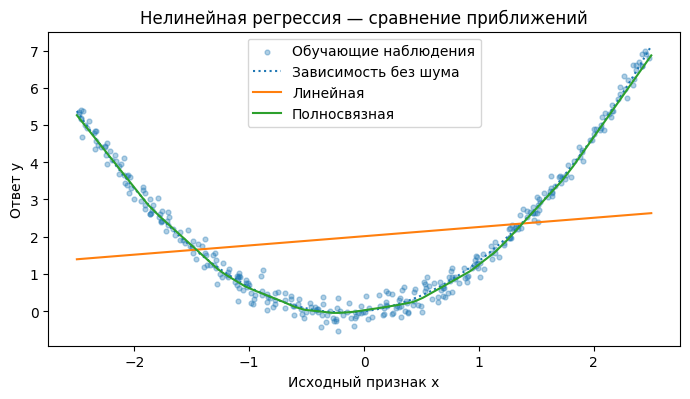

In [33]:
curve_grid_raw = torch.linspace(-2.5, 2.5, 250).reshape(-1, 1)
curve_grid = (curve_grid_raw - curve_mean) / curve_scale
plt.figure(figsize=(7, 4.1))
plt.scatter(X_curve_raw[curve_train_idx, 0], y_curve_raw[curve_train_idx, 0],
            s=12, alpha=0.35, label="Обучающие наблюдения")
plt.plot(curve_grid_raw[:, 0], (curve_grid_raw ** 2 + 0.35 * curve_grid_raw)[:, 0],
         ":", label="Зависимость без шума")
for name, model in curve_models.items():
    with torch.no_grad():
        prediction = model(curve_grid.to(device)).cpu().numpy().ravel()
    plt.plot(curve_grid_raw[:, 0], prediction, label=name)
plt.xlabel("Исходный признак x")
plt.ylabel("Ответ y")
plt.title("Нелинейная регрессия — сравнение приближений")
plt.legend()
plt.tight_layout()
plt.show()

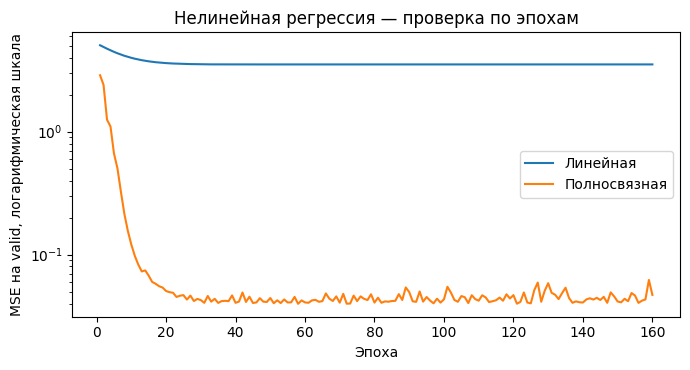

In [34]:
plt.figure(figsize=(7, 3.8))
for name, history in curve_histories.items():
    plt.plot(history.epoch, history.valid_mse, label=name)
plt.yscale("log")
plt.xlabel("Эпоха")
plt.ylabel("MSE на valid, логарифмическая шкала")
plt.title("Нелинейная регрессия — проверка по эпохам")
plt.legend()
plt.tight_layout()
plt.show()

### 5.5. Метрики обученной модели

После восстановления сохранённых параметров ещё раз получим ответы на `train` и `test`.
Теперь каждая метрика относится к одному состоянию модели.
Для сравнения добавим постоянный прогноз по среднему ответу обучающей части.

In [35]:
curve_rows = []
for name, model in curve_models.items():
    model.eval()
    for part, loader in [("train", curve_train_eval_loader), ("test", curve_test_loader)]:
        all_targets = []
        all_predictions = []
        with torch.no_grad():
            for x_batch, y_batch in loader:
                prediction = model(x_batch.to(device))
                all_predictions.append(prediction.cpu())
                all_targets.append(y_batch)
        targets = torch.cat(all_targets).numpy()
        predictions = torch.cat(all_predictions).numpy()
        curve_rows.append({
            "Модель": name, "Выборка": part,
            **regression_metrics(targets, predictions)
        })

curve_rows.append({
    "Модель": "Среднее train", "Выборка": "test",
    **regression_metrics(y_curve_test, np.full(len(y_curve_test), y_curve_train.mean().item()))
})
curve_results = pd.DataFrame(curve_rows)
display(curve_results.round(4))

,Модель,Выборка,MAE,RMSE,R²
0,Линейная,train,1.5941,1.8710,0.0367
1,Линейная,test,1.7277,1.9750,0.1022
2,Полносвязная,train,0.1621,0.2033,0.9886
3,Полносвязная,test,0.1769,0.2206,0.9888
4,Среднее train,test,1.8170,2.0871,-0.0027


## 6. Бинарная классификация

### 6.1. От вещественного ответа к вероятности класса

В бинарной задаче метка принимает значения 0 или 1.
Пусть модель выдаёт одно число $z$, называемое логитом.
Вероятность класса 1 в принятой модели распределения зададим сигмоидой

$$p=\sigma(z)=\frac{1}{1+e^{-z}}.$$

Для линейного логита $z=w^Tx+b$ получаем логистическую регрессию.
В полносвязной сети перед последним линейным слоем появляются скрытые слои.
Порог $p\geq0{,}5$ соответствует условию $z\geq0$.

Бинарная перекрёстная энтропия имеет вид

$$L=-\frac1N\sum_i\bigl[y_i\log p_i+(1-y_i)\log(1-p_i)\bigr].$$

`BCEWithLogitsLoss` принимает **логиты**, а не готовые вероятности. Она объединяет преобразование и расчёт потерь в численно устойчивом виде [9].
Поэтому отдельную `Sigmoid` в конец обучаемой модели не добавляем.

In [36]:
example_logits = torch.tensor([[-2.], [0.], [2.]])
example_targets = torch.tensor([[0.], [1.], [1.]])
example_probabilities = torch.sigmoid(example_logits)
manual_bce = -(example_targets * torch.log(example_probabilities)
               + (1 - example_targets) * torch.log1p(-example_probabilities)).mean()
ready_bce = nn.BCEWithLogitsLoss()(example_logits, example_targets)
print("Вероятности", example_probabilities.flatten())
print("Метки по вероятностям", (example_probabilities >= 0.5).long().flatten())
print("Метки по логитам", (example_logits >= 0).long().flatten())
print("BCE вручную и готовая", manual_bce.item(), ready_bce.item())

Вероятности tensor([0.1192, 0.5000, 0.8808])
Метки по вероятностям tensor([0, 1, 1])
Метки по логитам tensor([0, 1, 1])
BCE вручную и готовая 0.3156677484512329 0.3156677782535553


В ручном примере логиты невелики, поэтому прямое вычисление через логарифмы подходит для проверки формулы.
В обучении используем `BCEWithLogitsLoss`.
И выходы, и ответы далее имеют форму `(B, 1)`. Метки передаются как `float32`, хотя содержат только нули и единицы.

### 6.2. Создадим два класса и подготовим признаки

Функция `make_moons` создаёт точки двух полумесяцев с управляемым шумом [12].
У каждого объекта два признака — координаты на плоскости.
Разделим 900 объектов в пропорции 60/20/20 с сохранением приблизительных долей классов через `stratify`.

Вместо ручного вычисления среднего и стандартного отклонения применим `StandardScaler`.
`fit` вычисляет статистики по обучающей части, а `transform` применяет уже найденные значения [11].
Это тот же принцип, который использовался в регрессии.

In [37]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

X_binary_raw, y_binary_raw = make_moons(n_samples=900, noise=0.22, random_state=42)
binary_train_idx, binary_test_idx = train_test_split(
    np.arange(900), test_size=0.2, random_state=42, stratify=y_binary_raw
)
binary_train_idx, binary_valid_idx = train_test_split(
    binary_train_idx, test_size=0.25, random_state=42,
    stratify=y_binary_raw[binary_train_idx]
)
binary_scaler = StandardScaler().fit(X_binary_raw[binary_train_idx])
X_binary_train = torch.tensor(binary_scaler.transform(X_binary_raw[binary_train_idx]), dtype=torch.float32)
X_binary_valid = torch.tensor(binary_scaler.transform(X_binary_raw[binary_valid_idx]), dtype=torch.float32)
X_binary_test = torch.tensor(binary_scaler.transform(X_binary_raw[binary_test_idx]), dtype=torch.float32)
y_binary_train = torch.tensor(y_binary_raw[binary_train_idx], dtype=torch.float32).reshape(-1, 1)
y_binary_valid = torch.tensor(y_binary_raw[binary_valid_idx], dtype=torch.float32).reshape(-1, 1)
y_binary_test = torch.tensor(y_binary_raw[binary_test_idx], dtype=torch.float32).reshape(-1, 1)
print("Признаки", X_binary_train.shape, X_binary_train.dtype)
print("Метки", y_binary_train.shape, y_binary_train.dtype)
print("Размеры частей", len(binary_train_idx), len(binary_valid_idx), len(binary_test_idx))

Признаки torch.Size([540, 2]) torch.float32
Метки torch.Size([540, 1]) torch.float32
Размеры частей 540 180 180


### 6.3. Модели и функции потерь

Один линейный слой задаёт логистическую регрессию.
Вторая модель содержит два скрытых слоя по 16 значений.
Обе возвращают один логит для каждого объекта.

Используем `BCEWithLogitsLoss`.
Класс получим сравнением логита с нулём.
Для выбора эпохи будем минимизировать потерю на `valid`.
Долю верных ответов сохраним отдельно.

In [38]:
binary_train_dataset = TensorDataset(X_binary_train, y_binary_train)
binary_valid_dataset = TensorDataset(X_binary_valid, y_binary_valid)
binary_test_dataset = TensorDataset(X_binary_test, y_binary_test)
binary_valid_loader = DataLoader(binary_valid_dataset, batch_size=128, shuffle=False)
binary_test_loader = DataLoader(binary_test_dataset, batch_size=128, shuffle=False)
binary_train_eval_loader = DataLoader(binary_train_dataset, batch_size=128, shuffle=False)

torch.manual_seed(42)
binary_models = {
    "Логистическая регрессия": nn.Sequential(nn.Linear(2, 1)).to(device),
    "Полносвязная сеть": nn.Sequential(
        nn.Linear(2, 16), nn.ReLU(),
        nn.Linear(16, 16), nn.ReLU(),
        nn.Linear(16, 1)
    ).to(device),
}
binary_loss_function = nn.BCEWithLogitsLoss()

In [39]:
binary_histories = {}
binary_best_epochs = {}

for name, model in binary_models.items():
    train_loader = DataLoader(
        binary_train_dataset, batch_size=64, shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    history = []
    best_valid = float("inf")

    for epoch in range(1, 101):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = binary_loss_function(logits, y_batch)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(y_batch)
            train_correct += ((logits >= 0) == (y_batch == 1)).sum().item()

        model.eval()
        valid_loss_sum = 0.0
        valid_correct = 0
        with torch.no_grad():
            for x_batch, y_batch in binary_valid_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)
                logits = model(x_batch)
                loss = binary_loss_function(logits, y_batch)
                valid_loss_sum += loss.item() * len(y_batch)
                valid_correct += ((logits >= 0) == (y_batch == 1)).sum().item()

        train_bce = train_loss_sum / len(binary_train_dataset)
        valid_bce = valid_loss_sum / len(binary_valid_dataset)
        train_accuracy = train_correct / len(binary_train_dataset)
        valid_accuracy = valid_correct / len(binary_valid_dataset)
        history.append([epoch, train_bce, valid_bce, train_accuracy, valid_accuracy])
        if valid_bce < best_valid:
            best_valid = valid_bce
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    binary_best_epochs[name] = best_epoch
    binary_histories[name] = pd.DataFrame(
        history, columns=["epoch", "train_bce", "valid_bce", "train_accuracy", "valid_accuracy"]
    )

На графиках сравним потери и долю верных ответов по эпохам.
Обучающие значения накоплены по пакетам при меняющихся весах.
Проверочные значения вычислены после завершения эпохи.
Потеря может уменьшаться и тогда, когда выбранные метки ещё не меняются.

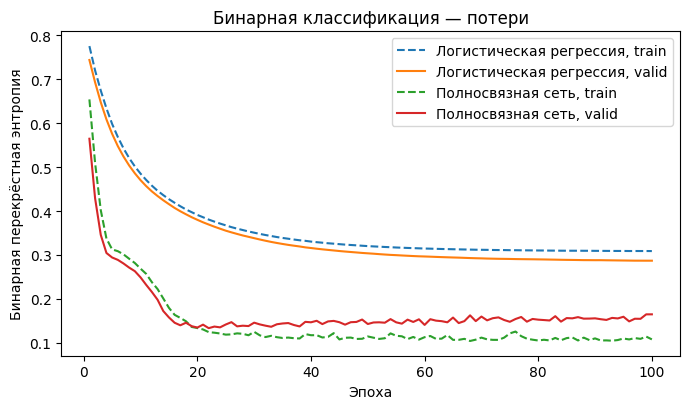

In [40]:
plt.figure(figsize=(7, 4.2))
for name, history in binary_histories.items():
    plt.plot(history.epoch, history.train_bce, "--", label=f"{name}, train")
    plt.plot(history.epoch, history.valid_bce, label=f"{name}, valid")
plt.xlabel("Эпоха")
plt.ylabel("Бинарная перекрёстная энтропия")
plt.title("Бинарная классификация — потери")
plt.legend()
plt.tight_layout()
plt.show()

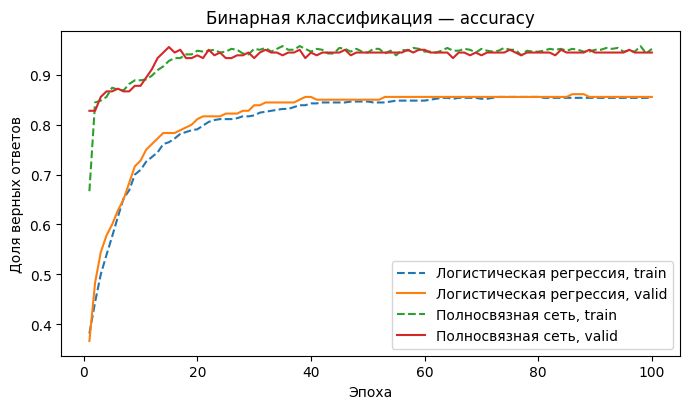

In [41]:
plt.figure(figsize=(7, 4.2))
for name, history in binary_histories.items():
    plt.plot(history.epoch, history.train_accuracy, "--", label=f"{name}, train")
    plt.plot(history.epoch, history.valid_accuracy, label=f"{name}, valid")
plt.xlabel("Эпоха")
plt.ylabel("Доля верных ответов")
plt.title("Бинарная классификация — accuracy")
plt.legend()
plt.tight_layout()
plt.show()

### 6.4. Разделяющие границы

Создадим сетку в исходных координатах и масштабируем её теми же параметрами, что и данные.
Получим логиты модели и переведём их в вероятности через сигмоиду.
Вернём вектор вероятностей к форме сетки.

`plt.contour` строит линии заданных значений.
Линия вероятности 0.5 отделяет два предсказываемых класса.
Для линейного логита она задаётся уравнением $w^Tx+b=0$.
На рисунках покажем объекты `valid`.

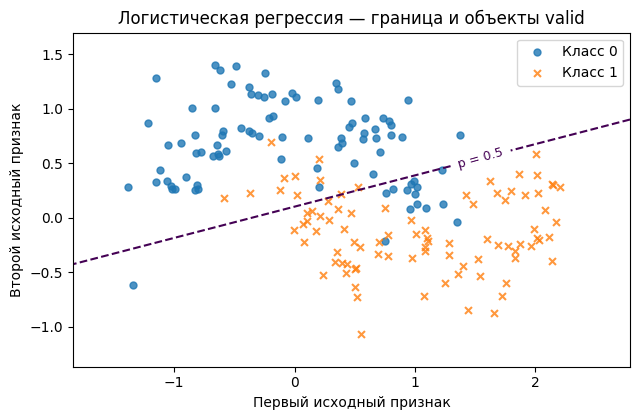

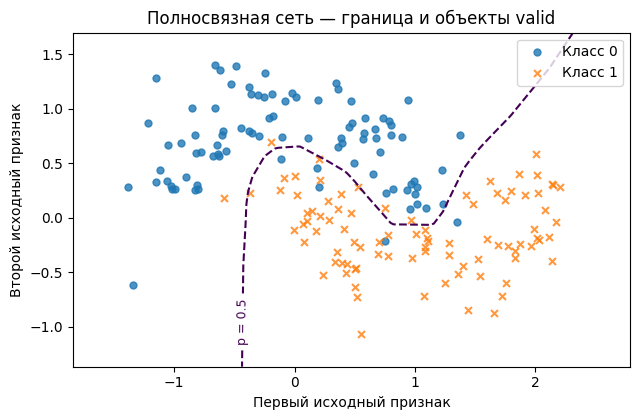

In [42]:
binary_view = X_binary_raw[np.r_[binary_train_idx, binary_valid_idx]]
x_limits = (binary_view[:, 0].min() - 0.3, binary_view[:, 0].max() + 0.3)
y_limits = (binary_view[:, 1].min() - 0.3, binary_view[:, 1].max() + 0.3)
gx, gy = np.meshgrid(np.linspace(*x_limits, 180), np.linspace(*y_limits, 180))
grid_raw = np.column_stack([gx.ravel(), gy.ravel()])
grid_tensor = torch.tensor(binary_scaler.transform(grid_raw), dtype=torch.float32).to(device)

for name, model in binary_models.items():
    with torch.no_grad():
        probabilities = torch.sigmoid(model(grid_tensor)).cpu().numpy().reshape(gx.shape)
    plt.figure(figsize=(6.5, 4.3))
    contours = plt.contour(gx, gy, probabilities, levels=[0.5], linestyles="--")
    plt.clabel(contours, fmt={0.5: "p = 0.5"}, inline=True, fontsize=9)
    for label, marker in [(0, "o"), (1, "x")]:
        selected = binary_valid_idx[y_binary_raw[binary_valid_idx] == label]
        plt.scatter(X_binary_raw[selected, 0], X_binary_raw[selected, 1],
                    marker=marker, s=25, alpha=0.8, label=f"Класс {label}")
    plt.xlim(x_limits)
    plt.ylim(y_limits)
    plt.xlabel("Первый исходный признак")
    plt.ylabel("Второй исходный признак")
    plt.title(f"{name} — граница и объекты valid")
    plt.legend()
    plt.tight_layout()
    plt.show()

### 6.5. Проверим классификаторы на тестовой части

Accuracy показывает долю верных меток.
Для каждого класса можно рассчитать F1 как $2TP/(2TP+FP+FN)$.
Macro-F1 усредняет F1 по классам с одинаковыми весами.
Это позволяет учитывать каждый класс отдельно, хотя ни одна из этих метрик не заменяет разбор ошибок.

Порог 0.5 выбран заранее и не подбирается по тесту.
Если в прикладной задаче требуется другой баланс ошибок, порог выбирают на проверочных данных.
В таблицу добавим правило, которое всегда отвечает наиболее частым классом обучающей части.

In [43]:
binary_rows = []
for name, model in binary_models.items():
    model.eval()
    for part, loader in [("train", binary_train_eval_loader), ("test", binary_test_loader)]:
        all_targets = []
        all_predictions = []
        with torch.no_grad():
            for x_batch, y_batch in loader:
                logits = model(x_batch.to(device))
                all_predictions.append((logits >= 0).long().cpu().reshape(-1))
                all_targets.append(y_batch.reshape(-1))
        targets = torch.cat(all_targets).numpy()
        predictions = torch.cat(all_predictions).numpy()
        binary_rows.append({
            "Модель": name, "Выборка": part,
            "Accuracy": accuracy_score(targets, predictions),
            "Macro-F1": f1_score(targets, predictions, average="macro", zero_division=0),
        })

binary_majority = np.bincount(y_binary_raw[binary_train_idx]).argmax()
binary_constant = np.full(len(y_binary_test), binary_majority)
binary_rows.append({
    "Модель": "Частый класс train", "Выборка": "test",
    "Accuracy": accuracy_score(y_binary_test.numpy().ravel(), binary_constant),
    "Macro-F1": f1_score(y_binary_test.numpy().ravel(), binary_constant,
                         average="macro", zero_division=0),
})
binary_results = pd.DataFrame(binary_rows)
display(binary_results.round(4))

,Модель,Выборка,Accuracy,Macro-F1
0,Логистическая регрессия,train,0.8537,0.8537
1,Логистическая регрессия,test,0.9111,0.9110
2,Полносвязная сеть,train,0.9481,0.9481
3,Полносвязная сеть,test,0.9444,0.9444
4,Частый класс train,test,0.5000,0.3333


## 7. Многоклассовая классификация табличных данных

### 7.1. Один логит для каждого класса

Для $C$ взаимоисключающих классов модель выдаёт вектор из $C$ логитов.
Вероятности вычисляются по строкам с помощью softmax.

$$p_{ic}=\frac{e^{z_{ic}}}{\sum_{j=1}^{C}e^{z_{ij}}},\qquad
L=-\frac1N\sum_i\log p_{i,y_i}.$$

`CrossEntropyLoss` принимает исходные логиты [15].
В данном варианте задачи правильные ответы задаются целочисленными номерами классов от 0 до $C-1$.
У логитов форма `(B, C)`, у меток — `(B,)` и тип `torch.long`.
В отличие от бинарного примера, дополнительная ось длины один для меток здесь не нужна.

Для выбора метки достаточно `argmax(dim=1)` по логитам. Softmax нужен, когда требуются сами вероятности.
Он не меняет положение максимума.

In [44]:
multiclass_logits = torch.tensor([[2., 0., -1.], [0.2, 0.5, 1.5]])
multiclass_targets = torch.tensor([0, 2], dtype=torch.long)
multiclass_probabilities = torch.softmax(multiclass_logits, dim=1)
manual_ce = -torch.log(multiclass_probabilities[torch.arange(2), multiclass_targets]).mean()
ready_ce = nn.CrossEntropyLoss()(multiclass_logits, multiclass_targets)
print("Вероятности\n", multiclass_probabilities)
print("Метки", multiclass_logits.argmax(dim=1))
print("Потеря вручную и готовая", manual_ce.item(), ready_ce.item())

Вероятности
 tensor([[0.8438, 0.1142, 0.0420],
        [0.1661, 0.2243, 0.6096]])
Метки tensor([0, 2])
Потеря вручную и готовая 0.3323965072631836 0.3323965072631836


### 7.2. Прочитаем Wine

Wine содержит 178 объектов, 13 числовых признаков химического анализа и три класса [13].
Набор небольшой, поэтому даже одна ошибка заметно меняет долю правильных ответов на отложенной части.

Здесь снова сравним один линейный слой и полносвязную сеть.
У входа 13 признаков, а у последнего слоя три выхода.
В предварительном просмотре выведем первые пять признаков и метку. При обучении используются все 13 признаков.

In [45]:
from sklearn.datasets import load_wine

wine = load_wine()
X_wine_raw = wine.data
wine_labels = wine.target
wine_frame = pd.DataFrame(X_wine_raw, columns=wine.feature_names)
wine_frame["class"] = wine_labels
display(wine_frame[[*wine.feature_names[:5], "class"]].head().round(3))
print("Размер", X_wine_raw.shape)
print("Классы", np.unique(wine_labels), "Число объектов по классам", np.bincount(wine_labels))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,class
0,14.23,1.71,2.43,15.6,127.0,0
1,13.20,1.78,2.14,11.2,100.0,0
2,13.16,2.36,2.67,18.6,101.0,0
3,14.37,1.95,2.50,16.8,113.0,0
4,13.24,2.59,2.87,21.0,118.0,0


Размер (178, 13)
Классы [0 1 2] Число объектов по классам [59 71 48]


### 7.3. Подготовим части и типы данных

Доли частей оставим прежними. Из-за округления число объектов будет равно 106, 36 и 36.
Масштабирование обучается только на первых 106 объектах, выделенных в `train`.
Названия и порядок столбцов сохраняем, поскольку они понадобятся при применении модели.

In [46]:
wine_train_idx, wine_test_idx = train_test_split(
    np.arange(len(wine_labels)), test_size=0.2, random_state=42, stratify=wine_labels
)
wine_train_idx, wine_valid_idx = train_test_split(
    wine_train_idx, test_size=0.25, random_state=42, stratify=wine_labels[wine_train_idx]
)
wine_scaler = StandardScaler().fit(X_wine_raw[wine_train_idx])
X_wine_train = torch.tensor(wine_scaler.transform(X_wine_raw[wine_train_idx]), dtype=torch.float32)
X_wine_valid = torch.tensor(wine_scaler.transform(X_wine_raw[wine_valid_idx]), dtype=torch.float32)
X_wine_test = torch.tensor(wine_scaler.transform(X_wine_raw[wine_test_idx]), dtype=torch.float32)
y_wine_train = torch.tensor(wine_labels[wine_train_idx], dtype=torch.long)
y_wine_valid = torch.tensor(wine_labels[wine_valid_idx], dtype=torch.long)
y_wine_test = torch.tensor(wine_labels[wine_test_idx], dtype=torch.long)
print("Размеры частей", len(y_wine_train), len(y_wine_valid), len(y_wine_test))
print("Признаки", X_wine_train.shape, X_wine_train.dtype)
print("Метки", y_wine_train.shape, y_wine_train.dtype)

Размеры частей 106 36 36
Признаки torch.Size([106, 13]) torch.float32
Метки torch.Size([106]) torch.int64


### 7.4. Архитектуры и обучение

Модель `Linear(13, 3)` вместе с `CrossEntropyLoss` задаёт многоклассовую логистическую регрессию.
Полносвязная сеть использует скрытые слои размеров 24 и 12 с `ReLU`.
Обе модели возвращают три логита без заключительного `Softmax`.

Метку получаем через `argmax(dim=1)`.
В обучении и валидации считаем среднюю потерю и долю правильных ответов.
Для каждой модели сохраняем параметры эпохи с наименьшей потерей на `valid`.

In [47]:
wine_train_dataset = TensorDataset(X_wine_train, y_wine_train)
wine_valid_dataset = TensorDataset(X_wine_valid, y_wine_valid)
wine_test_dataset = TensorDataset(X_wine_test, y_wine_test)
wine_valid_loader = DataLoader(wine_valid_dataset, batch_size=64, shuffle=False)
wine_test_loader = DataLoader(wine_test_dataset, batch_size=64, shuffle=False)
wine_train_eval_loader = DataLoader(wine_train_dataset, batch_size=64, shuffle=False)

torch.manual_seed(42)
wine_models = {
    "Линейная": nn.Sequential(nn.Linear(13, 3)).to(device),
    "Полносвязная": nn.Sequential(
        nn.Linear(13, 24), nn.ReLU(),
        nn.Linear(24, 12), nn.ReLU(),
        nn.Linear(12, 3)
    ).to(device),
}
wine_loss_function = nn.CrossEntropyLoss()

In [48]:
wine_histories = {}
wine_best_epochs = {}

for name, model in wine_models.items():
    train_loader = DataLoader(
        wine_train_dataset, batch_size=32, shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    history = []
    best_valid = float("inf")

    for epoch in range(1, 101):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = wine_loss_function(logits, y_batch)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(y_batch)
            train_correct += (logits.argmax(dim=1) == y_batch).sum().item()

        model.eval()
        valid_loss_sum = 0.0
        valid_correct = 0
        with torch.no_grad():
            for x_batch, y_batch in wine_valid_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)
                logits = model(x_batch)
                loss = wine_loss_function(logits, y_batch)
                valid_loss_sum += loss.item() * len(y_batch)
                valid_correct += (logits.argmax(dim=1) == y_batch).sum().item()

        train_ce = train_loss_sum / len(wine_train_dataset)
        valid_ce = valid_loss_sum / len(wine_valid_dataset)
        train_accuracy = train_correct / len(wine_train_dataset)
        valid_accuracy = valid_correct / len(wine_valid_dataset)
        history.append([epoch, train_ce, valid_ce, train_accuracy, valid_accuracy])
        if valid_ce < best_valid:
            best_valid = valid_ce
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    wine_best_epochs[name] = best_epoch
    wine_histories[name] = pd.DataFrame(
        history, columns=["epoch", "train_ce", "valid_ce", "train_accuracy", "valid_accuracy"]
    )

### 7.5. Выберем модель по проверочной части

Для последующего сохранения заранее примем правило выбора по минимальной `valid CE`.
В таблице accuracy относится именно к сохранённой эпохе, а не к отдельно выбранному максимуму accuracy.
После такого выбора рассчитаем тестовые показатели обеих заранее заданных архитектур.

In [49]:
wine_selection_rows = []
for name, history in wine_histories.items():
    row = history.loc[history.epoch == wine_best_epochs[name]].iloc[0]
    wine_selection_rows.append({
        "Модель": name, "Эпоха": wine_best_epochs[name],
        "CE valid": row.valid_ce, "Accuracy valid": row.valid_accuracy,
        "Параметров": sum(p.numel() for p in wine_models[name].parameters()),
    })
wine_selection = pd.DataFrame(wine_selection_rows)
display(wine_selection.round(4))
wine_selected_name = min(wine_histories, key=lambda name: wine_histories[name].valid_ce.min())
print("Для сохранения выбрана модель", wine_selected_name)

,Модель,Эпоха,CE valid,Accuracy valid,Параметров
0,Линейная,100,0.0512,1.0000,42
1,Полносвязная,8,0.0419,0.9722,675


Для сохранения выбрана модель Полносвязная


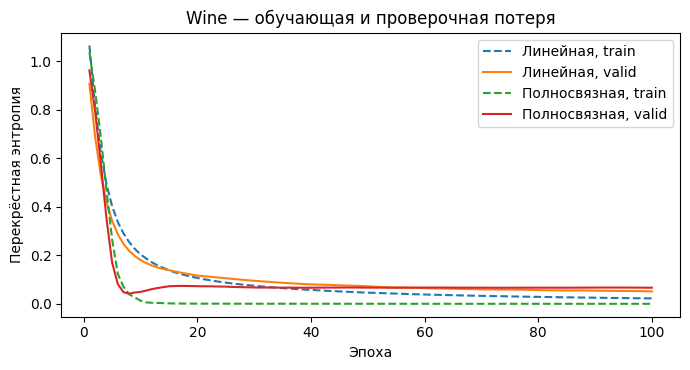

In [50]:
plt.figure(figsize=(7, 3.8))
for name, history in wine_histories.items():
    plt.plot(history.epoch, history.train_ce, "--", label=f"{name}, train")
    plt.plot(history.epoch, history.valid_ce, label=f"{name}, valid")
plt.xlabel("Эпоха")
plt.ylabel("Перекрёстная энтропия")
plt.title("Wine — обучающая и проверочная потеря")
plt.legend()
plt.tight_layout()
plt.show()

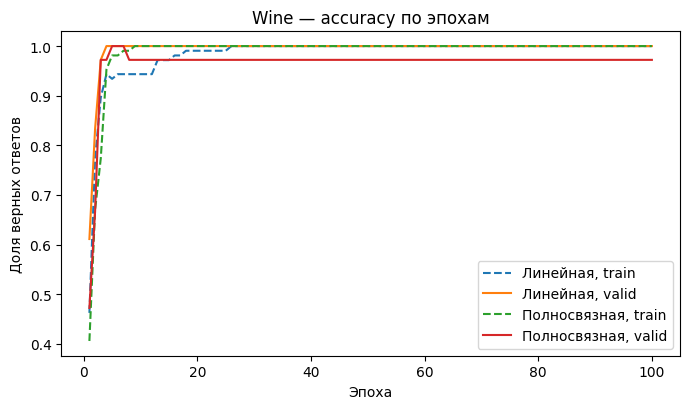

In [51]:
plt.figure(figsize=(7, 4.2))
for name, history in wine_histories.items():
    plt.plot(history.epoch, history.train_accuracy, "--", label=f"{name}, train")
    plt.plot(history.epoch, history.valid_accuracy, label=f"{name}, valid")
plt.xlabel("Эпоха")
plt.ylabel("Доля верных ответов")
plt.title("Wine — accuracy по эпохам")
plt.legend()
plt.tight_layout()
plt.show()

### 7.6. Метрики на train и test

Возьмём сохранённое состояние каждой модели и получим метки по пакетам.
Для каждой части объединим правильные ответы и предсказания в два вектора.
По ним рассчитаем accuracy и macro-F1.

In [52]:
wine_predictions = {}
wine_rows = []
for name, model in wine_models.items():
    model.eval()
    for part, loader in [("train", wine_train_eval_loader), ("test", wine_test_loader)]:
        all_targets = []
        all_predictions = []
        with torch.no_grad():
            for x_batch, y_batch in loader:
                logits = model(x_batch.to(device))
                all_predictions.append(logits.argmax(dim=1).cpu())
                all_targets.append(y_batch)
        targets = torch.cat(all_targets).numpy()
        predictions = torch.cat(all_predictions).numpy()
        if part == "test":
            wine_predictions[name] = predictions
        wine_rows.append({
            "Модель": name, "Выборка": part,
            "Accuracy": accuracy_score(targets, predictions),
            "Macro-F1": f1_score(targets, predictions, average="macro", zero_division=0),
        })
wine_results = pd.DataFrame(wine_rows)
display(wine_results.round(4))

,Модель,Выборка,Accuracy,Macro-F1
0,Линейная,train,1.0000,1.0000
1,Линейная,test,0.9722,0.9710
2,Полносвязная,train,1.0000,1.0000
3,Полносвязная,test,0.9444,0.9407


Матрица ошибок показывает, какие классы модель путает между собой.
Строки соответствуют правильным классам, столбцы — предсказанным.
На диагонали стоят верные ответы.
Построим матрицу для модели, которую выбрали по `valid`.

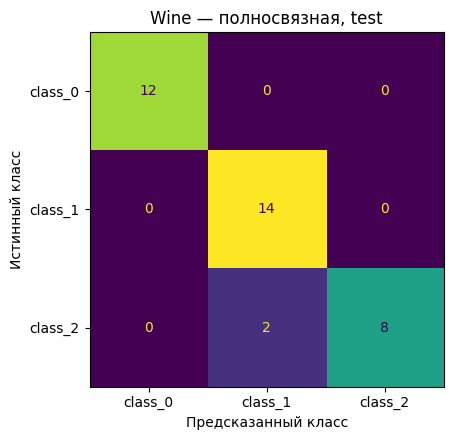

In [53]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_wine_test.numpy(), wine_predictions[wine_selected_name], labels=[0, 1, 2],
    display_labels=wine.target_names, colorbar=False, ax=ax
)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title(f"Wine — {wine_selected_name.lower()}, test")
plt.tight_layout()
plt.show()

## 8. Сохранение и применение модели

### 8.1. Состояние модели и подготовка признаков

Для применения модели нужны веса, архитектура и порядок признаков.
Нужны также параметры масштабирования.
Новые данные должны пройти то же преобразование, что и обучающие.

Сохраним словарь из тензоров и простых значений Python [14].
В него включим выбранную архитектуру и её размеры.
Состояние оптимизатора понадобилось бы при продолжении обучения, но для получения ответов оно не требуется.

In [54]:
selected_model = wine_models[wine_selected_name]
wine_checkpoint = {
    "state_dict": {name: value.detach().cpu().clone()
                   for name, value in selected_model.state_dict().items()},
    "model_name": wine_selected_name,
    "feature_names": list(wine.feature_names),
    "class_names": [str(name) for name in wine.target_names],
    "mean": torch.tensor(wine_scaler.mean_, dtype=torch.float64),
    "scale": torch.tensor(wine_scaler.scale_, dtype=torch.float64),
    "widths": [13, 3] if wine_selected_name == "Линейная" else [13, 24, 12, 3],
    "hidden_activation": "ReLU" if wine_selected_name == "Полносвязная" else None,
}
torch.save(wine_checkpoint, "wine_classifier.pt")

### 8.2. Загрузка

Загрузим сохранённый словарь на CPU с `weights_only=True` [14].
Создадим такую же архитектуру и передадим веса в `load_state_dict`.
Затем переведём модель в режим `eval()`.
Здесь используется собственный файл, а не файл из неизвестного источника.

In [55]:
loaded_checkpoint = torch.load("wine_classifier.pt", map_location="cpu", weights_only=True)

if loaded_checkpoint["model_name"] == "Линейная":
    restored_model = nn.Sequential(nn.Linear(13, 3))
else:
    restored_model = nn.Sequential(
        nn.Linear(13, 24), nn.ReLU(),
        nn.Linear(24, 12), nn.ReLU(),
        nn.Linear(12, 3)
    )

restored_model.load_state_dict(loaded_checkpoint["state_dict"])
restored_model.eval()

Sequential(
  (0): Linear(in_features=13, out_features=24, bias=True)
  (1): ReLU()
  (2): Linear(in_features=24, out_features=12, bias=True)
  (3): ReLU()
  (4): Linear(in_features=12, out_features=3, bias=True)
)

### 8.3. Ответы для строк таблицы

Выберем пять объектов в исходных единицах.
Сначала расположим признаки в сохранённом порядке, затем применим сохранённые средние и масштабы.
Масштабирование выполняется в `float64`, как в `StandardScaler`.
В модель передаём значения типа `float32`.

Вероятности получим через `softmax`, а номера классов через `argmax`.

In [56]:
new_objects = wine_frame.loc[wine_test_idx[:5], loaded_checkpoint["feature_names"]]
raw_values = torch.tensor(new_objects.to_numpy(), dtype=torch.float64)
prepared_values = ((raw_values - loaded_checkpoint["mean"]) / loaded_checkpoint["scale"]).float()

with torch.no_grad():
    logits = restored_model(prepared_values)
    probabilities = torch.softmax(logits, dim=1)
    labels = logits.argmax(dim=1)

result_table = pd.DataFrame(probabilities.numpy(), columns=loaded_checkpoint["class_names"])
result_table["Предсказанный класс"] = labels.numpy()
result_table["Правильный класс"] = y_wine_test[:5].numpy()
display(result_table.round(4))

,class_0,class_1,class_2,Предсказанный класс,Правильный класс
0,0.9998,0.0001,0.0000,0,0
1,0.0001,0.9643,0.0356,1,2
2,0.9964,0.0030,0.0006,0,0
3,0.0033,0.9918,0.0049,1,1
4,0.0025,0.9968,0.0007,1,1


## Памятка по трём постановкам

В таблице приведены соглашения, использованные в этой работе.
Во всех случаях признаки имеют форму `(B, d)` и тип `float32`.
Для классификации предполагается ровно одна истинная метка на объект.

| Задача | Последний слой | Выход модели | Правильный ответ | Функция потерь | Получение ответа |
|---|---|---|---|---|---|
| Регрессия с одним выходом | `Linear(h, 1)` | `(B, 1)`, вещественные числа | `(B, 1)`, `float32` | `MSELoss` | Сам выход модели |
| Бинарная классификация | `Linear(h, 1)` | `(B, 1)`, логиты | `(B, 1)`, `float32`, 0 или 1 | `BCEWithLogitsLoss` | `sigmoid` для вероятности, `logits >= 0` для метки |
| Классификация на C классов | `Linear(h, C)` | `(B, C)`, логиты | `(B,)`, `long`, от 0 до C−1 | `CrossEntropyLoss` | `softmax(dim=1)` для вероятностей, `argmax(dim=1)` для метки |

Для модели без скрытых слоёв $h=d$. При других способах задания целевых значений требования функций потерь могут отличаться.
Бинарную классификацию также можно задать двумя логитами и `CrossEntropyLoss`, но смешивать два соглашения в одном расчёте нельзя [9, 15].

## Источники и документация

[1] [Тензоры и взаимодействие с NumPy](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html).

[2] [Линейный слой `nn.Linear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html).

[3] [Контейнер `nn.Sequential`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html).

[4] [Автоматическое дифференцирование](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).

[5] [Средний квадрат ошибки `nn.MSELoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html).

[6] [Цикл оптимизации](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).

[7] [Dataset и DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html).

[8] [Модуль `nn.Module`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html) и [режимы вычисления градиентов](https://docs.pytorch.org/docs/stable/notes/autograd.html).

[9] [Бинарная перекрёстная энтропия `nn.BCEWithLogitsLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

[10] [Разделение данных `train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

[11] [Масштабирование `StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) и [предотвращение утечки данных](https://scikit-learn.org/stable/common_pitfalls.html).

[12] [Генератор `make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html).

[13] [Набор `load_wine`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).

[14] [Сохранение и загрузка моделей](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).

[15] [Многоклассовая потеря `nn.CrossEntropyLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).